In [2]:
import pandas as pd
import numpy as np 

%matplotlib inline
import matplotlib.pyplot as plt

import seaborn as sns

In [8]:
df_ride = pd.read_csv('/Users/alex1/Downloads/data5300data/ride_data.csv')

In [9]:
df_ride.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1402312 entries, 0 to 1402311
Data columns (total 16 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   ride_id                  1402312 non-null  object 
 1   rider_id                 1402312 non-null  object 
 2   driver_id                1367819 non-null  object 
 3   ride_type                1402312 non-null  object 
 4   upfront_fare             1397335 non-null  float64
 5   rider_paid_amount        1402312 non-null  float64
 6   eta_to_rider_pre_match   1334909 non-null  float64
 7   eta_to_rider_post_match  1367790 non-null  float64
 8   requested_at_local       1402312 non-null  object 
 9   accepted_at_local        1367790 non-null  object 
 10  arrived_at_local         1193519 non-null  object 
 11  picked_up_at_local       1193511 non-null  object 
 12  dropped_off_at_local     1193487 non-null  object 
 13  actual_time_to_arrival   1193491 non-null 

In [10]:
df_ride.head()

,ride_id,rider_id,driver_id,ride_type,upfront_fare,rider_paid_amount,eta_to_rider_pre_match,eta_to_rider_post_match,requested_at_local,accepted_at_local,arrived_at_local,picked_up_at_local,dropped_off_at_local,actual_time_to_arrival,cancellation_flag,rider_request_number
0,KCMXI4HAfLCjgHFR2qA1Lg==,AKTYnqStIa+/suWRUAQ60g==,c5U+DL4S+9Kd8xs0jW3ADg==,standard,12.13,17.40,60.0,21.0,2019-05-04 14:08:33.000 America/Los_Angeles,2019-05-04 14:08:43.775 America/Los_Angeles,2019-05-04 14:09:21.508 America/Los_Angeles,2019-05-04 14:10:02.000 America/Los_Angeles,2019-05-04 14:22:34.000 America/Los_Angeles,37.0,0,1
1,ERylrc+OvEb4gm84MxYmWQ==,ARxb2lRoxbrEgQgDEJIr7Q==,NaN,standard,77.76,1.00,60.0,NaN,2019-05-03 15:26:37.000 America/Los_Angeles,NaN,NaN,NaN,NaN,NaN,1,1
2,FKVvDcTRe0O1TDpg6uzLgQ==,ARxb2lRoxbrEgQgDEJIr7Q==,HBzAE1FuAnArUgou7Qetow==,standard,7.82,8.17,360.0,541.0,2019-05-10 19:26:29.000 America/Los_Angeles,2019-05-10 19:27:00.632 America/Los_Angeles,2019-05-10 19:37:22.502 America/Los_Angeles,2019-05-10 19:37:24.000 America/Los_Angeles,2019-05-10 19:44:22.000 America/Los_Angeles,621.0,0,2
3,ELtwBfng4uSyXpBseav1Bg==,AeWaFFe6cKFmfTEnEr6QBQ==,MX3XhXFZAjKpEDIRm5QoMg==,standard,14.76,14.82,60.0,126.0,2019-05-10 23:39:07.000 America/Los_Angeles,2019-05-10 23:39:32.725 America/Los_Angeles,2019-05-10 23:42:24.283 America/Los_Angeles,2019-05-10 23:42:28.000 America/Los_Angeles,2019-05-11 00:02:06.000 America/Los_Angeles,171.0,0,1
4,OmCaoDxSXwN3nJzg8Jwamw==,Au8G9PfP3KN3SUnTPO+mMQ==,lqj+gQA7gRITBlHwTCM8Rg==,standard,18.05,17.78,360.0,587.0,2019-05-08 13:52:08.000 America/Los_Angeles,2019-05-08 13:53:24.871 America/Los_Angeles,2019-05-08 14:03:34.987 America/Los_Angeles,2019-05-08 14:03:39.000 America/Los_Angeles,2019-05-08 14:18:35.000 America/Los_Angeles,610.0,0,1


In [11]:
df_ride['rider_id'].nunique()

530756

In [12]:
df_ride['cancellation_flag'].value_counts()

cancellation_flag
0    1195262
1     207050
Name: count, dtype: int64

In [13]:
df_experiment = pd.read_csv('/Users/alex1/Downloads/data5300data/experiment_data.csv')

In [14]:
df_experiment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530756 entries, 0 to 530755
Data columns (total 3 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   rider_id        530756 non-null  object 
 1   variant         530756 non-null  object 
 2   cancel_penalty  530756 non-null  float64
dtypes: float64(1), object(2)
memory usage: 12.1+ MB


In [15]:
df_experiment['rider_id'].nunique()

530756

In [16]:
df_experiment.groupby(['variant', 'cancel_penalty']).count()

,,rider_id
variant,cancel_penalty,
control,5.0,176856
treatment1,3.0,176900
treatment2,1.0,177000


Joining dataframes

In [17]:
df_combined = pd.merge(df_ride, df_experiment, on='rider_id', how='left')

In [18]:
df_combined.isna().sum()

ride_id                         0
rider_id                        0
driver_id                   34493
ride_type                       0
upfront_fare                 4977
rider_paid_amount               0
eta_to_rider_pre_match      67403
eta_to_rider_post_match     34522
requested_at_local              0
accepted_at_local           34522
arrived_at_local           208793
picked_up_at_local         208801
dropped_off_at_local       208825
actual_time_to_arrival     208821
cancellation_flag               0
rider_request_number            0
variant                         0
cancel_penalty                  0
dtype: int64

In [19]:
df = df_combined[['ride_id', 'rider_id', 'ride_type', 'upfront_fare', 'rider_paid_amount', 'cancellation_flag', 'rider_request_number', 'variant', 'cancel_penalty']]

In [20]:
df.describe().style.format('{:.3f}')

,upfront_fare,rider_paid_amount,cancellation_flag,rider_request_number,cancel_penalty
count,1397335.000,1402312.000,1402312.000,1402312.000,1402312.000
mean,14.065,13.207,0.148,3.614,2.986
std,10.961,11.868,0.355,4.043,1.630
min,2.750,0.000,0.000,1.000,1.000
25%,7.560,6.550,0.000,1.000,1.000
50%,10.460,10.070,0.000,2.000,3.000
75%,15.830,15.340,0.000,4.000,5.000
max,629.190,629.160,1.000,107.000,5.000


In [21]:
df['ride_id'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1402312 entries, 0 to 1402311
Series name: ride_id
Non-Null Count    Dtype 
--------------    ----- 
1402312 non-null  object
dtypes: object(1)
memory usage: 10.7+ MB


In [22]:
df[df['cancellation_flag'] == 1][[
    'variant', 'cancel_penalty', 'cancellation_flag']].groupby([
    'variant', 'cancel_penalty']).count()

,,cancellation_flag
variant,cancel_penalty,
control,5.0,46214
treatment1,3.0,72335
treatment2,1.0,88501


In [23]:
df[['variant', 'cancel_penalty', 'cancellation_flag']].groupby([
    'variant', 'cancel_penalty']).value_counts()

variant     cancel_penalty  cancellation_flag
control     5.0             0                    414762
                            1                     46214
treatment1  3.0             0                    398114
                            1                     72335
treatment2  1.0             0                    382386
                            1                     88501
Name: count, dtype: int64

In [24]:
from scipy.stats import chi2_contingency, ttest_ind

riders = df_combined.groupby(["rider_id", "variant"]).agg(Total_Rides=("ride_id", "count"), Total_Cancellations=("cancellation_flag", "sum")).reset_index()

# Create cancellation categories
riders["Cancellation_Category"] = pd.cut(
    riders["Total_Cancellations"],
    bins=[-1, 2, 5, float("inf")],
    labels=["Treatment 2", "Treatment 1", "Control"])

#CHI-SQUARE TEST
contingency_table = pd.crosstab(riders["variant"], riders["Cancellation_Category"])
chi2, p, dof, expected = chi2_contingency(contingency_table)
print("CHI-SQUARE TEST")
print(contingency_table)
print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

#WELCH T-TEST
control = riders[riders["variant"] == "control"]["Total_Cancellations"]
treatment1 = riders[riders["variant"] == "treatment1"]["Total_Cancellations"]
treatment2 = riders[riders["variant"] == "treatment2"]["Total_Cancellations"]
comparisons = [("Control vs Treatment 1", control, treatment1), ("Control vs Treatment 2", control, treatment2), ("Treatment 1 vs Treatment 2", treatment1, treatment2)]
print("\nWELCH T-TEST RESULTS")

for name, group1, group2 in comparisons:

    t_stat, p_value = ttest_ind(
        group1,
        group2,
        equal_var=False)

    print(name)
    print("T-statistic:", t_stat)
    print("P-value:", p_value)

summary = riders.groupby("variant").agg(Number_of_Riders=("rider_id", "count"), Average_Cancellations=("Total_Cancellations", "mean"), Total_Cancellations=("Total_Cancellations", "sum"))
print("SUMMARY STATISTICS")
print(summary)


CHI-SQUARE TEST
Cancellation_Category  Treatment 2  Treatment 1  Control
variant                                                 
control                     173678         2702      476
treatment1                  170577         4692     1631
treatment2                  168902         5621     2477
Chi-square statistic: 2414.5117926418834
P-value: 0.0
Degrees of freedom: 4

WELCH T-TEST RESULTS
Control vs Treatment 1
T-statistic: -42.95379747065901
P-value: 0.0
Control vs Treatment 2
T-statistic: -61.14003614849837
P-value: 0.0
Treatment 1 vs Treatment 2
T-statistic: -20.042291381995778
P-value: 2.6507913088037128e-89
SUMMARY STATISTICS
            Number_of_Riders  Average_Cancellations  Total_Cancellations
variant                                                                 
control               176856               0.261309                46214
treatment1            176900               0.408903                72335
treatment2            177000               0.500006           

In [27]:
# Group rides by individual rider
rider_data = (df.groupby(["rider_id", "variant", "cancel_penalty"]).agg(Total_Rides=("ride_id", "count"), Total_Cancellations=("cancellation_flag", "sum")).reset_index())
rider_data["Completed_Rides"] = (rider_data["Total_Rides"] - rider_data["Total_Cancellations"])
rider_data["Cancellation_Rate"] = (rider_data["Total_Cancellations"] / rider_data["Total_Rides"]) * 100
print(rider_data.head())


                   rider_id     variant  cancel_penalty  Total_Rides  \
0  +++3990cLNPGgaPm+ripGg==     control             5.0            1   
1  +++stf7DqWcT8LMTYbXrwA==     control             5.0            1   
2  ++07zTPYFhvA5Ug72kRd0w==  treatment1             3.0            2   
3  ++08hetKFBNoOO5XHAH/5A==  treatment2             1.0           11   
4  ++0YwCvnfyMWSNH3wpyP1g==  treatment2             1.0            1   

   Total_Cancellations  Completed_Rides  Cancellation_Rate  
0                    0                1           0.000000  
1                    1                0         100.000000  
2                    0                2           0.000000  
3                    5                6          45.454545  
4                    0                1           0.000000  


In [28]:
conditions = [rider_data["Total_Cancellations"].between(0, 2), rider_data["Total_Cancellations"].between(3, 5), rider_data["Total_Cancellations"] >= 6]
categories = ["Low-frequency", "Moderate-frequency", "High-frequency"]
rider_data["Cancellation_Category"] = np.select(conditions, categories, default="Unknown")

#Count riders in each classification
category_summary = (rider_data["Cancellation_Category"].value_counts().reindex(categories).to_frame("Number_of_Riders"))
category_summary["Percentage"] = (category_summary["Number_of_Riders"] / len(rider_data) * 100)
print(category_summary)


                       Number_of_Riders  Percentage
Cancellation_Category                              
Low-frequency                    513157   96.684164
Moderate-frequency                13015    2.452163
High-frequency                     4584    0.863674


In [29]:
# Compare cancellation categories by original experiment group
category_by_variant = pd.crosstab(rider_data["variant"], rider_data["Cancellation_Category"])
print(category_by_variant)

category_percentages = pd.crosstab(rider_data["variant"], rider_data["Cancellation_Category"], normalize="index") * 100
print("\nPercentage Distribution:")
print(category_percentages.round(2))


Cancellation_Category  High-frequency  Low-frequency  Moderate-frequency
variant                                                                 
control                           476         173678                2702
treatment1                       1631         170577                4692
treatment2                       2477         168902                5621

Percentage Distribution:
Cancellation_Category  High-frequency  Low-frequency  Moderate-frequency
variant                                                                 
control                          0.27          98.20                1.53
treatment1                       0.92          96.43                2.65
treatment2                       1.40          95.42                3.18


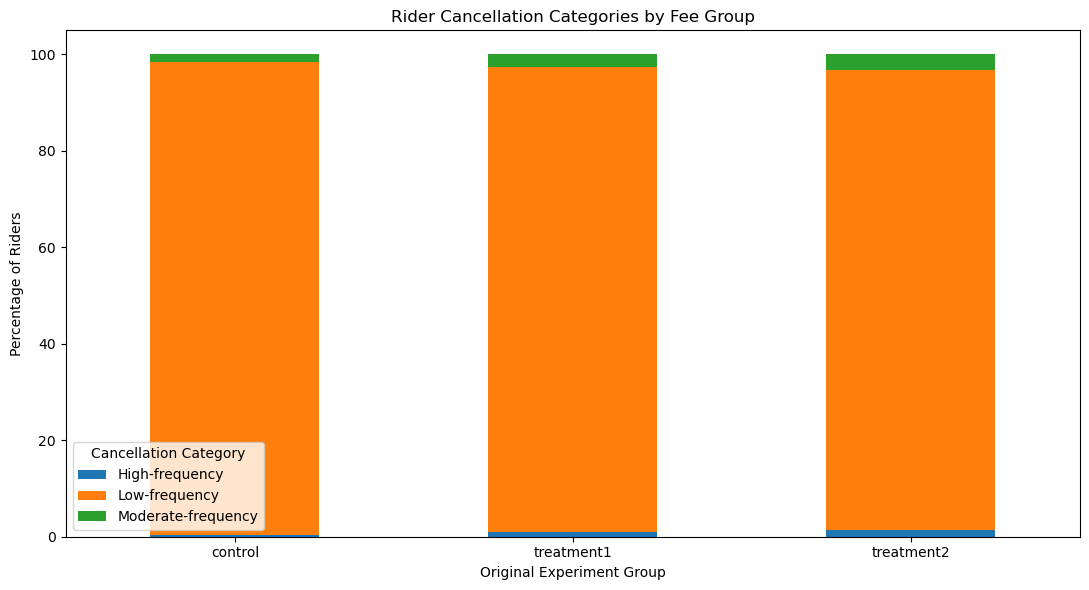

In [30]:
category_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6))

plt.title("Rider Cancellation Categories by Fee Group")
plt.xlabel("Original Experiment Group")
plt.ylabel("Percentage of Riders")
plt.legend(title="Cancellation Category")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


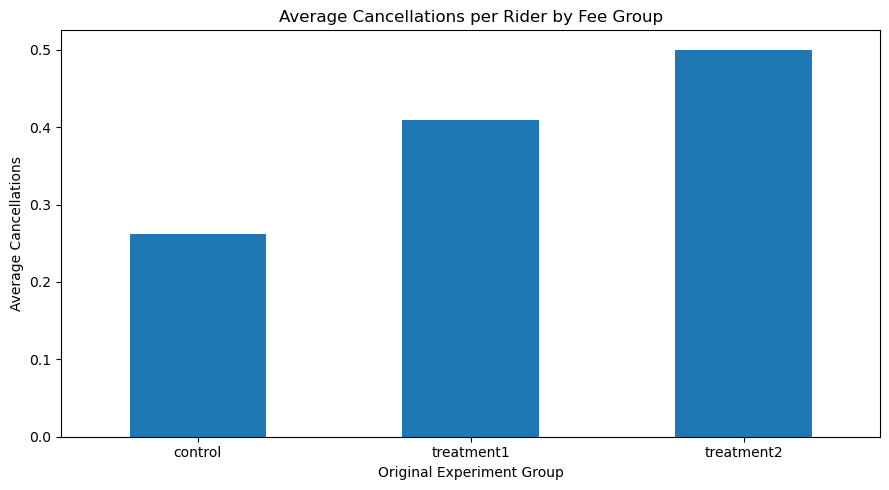

In [31]:
average_cancellations = (rider_data.groupby("variant")["Total_Cancellations"].mean())
average_cancellations.plot(
    kind="bar",
    figsize=(9, 5))

plt.title("Average Cancellations per Rider by Fee Group")
plt.xlabel("Original Experiment Group")
plt.ylabel("Average Cancellations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
